In [1]:
!pip install -q fsspec-xrootd xrootd

In [2]:
import argparse
import sys

import awkward as ak
import numpy as np
import uproot
import vector

vector.register_awkward()

In [3]:
from pathlib import Path
data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

# 1. Print all root files
root_files = sorted(list(data_dir.glob("*.root")))
print(f"Found {len(root_files)} ROOT files:")
for rf in root_files:
    print(" -", rf.name)

# 2. Inspect branches in the first file
if root_files:
    with uproot.open(root_files[0]) as f:
        tree = f["Events"]
        print(f"\nTotal events in {root_files[0].name}: {tree.num_entries}")
        print("\nAvailable feature branches:")
        print(tree.keys()[:25], f"... (+ {len(tree.keys()) - 25} more)" if len(tree.keys()) > 25 else "")

Found 8 ROOT files:
 - DY-test.root
 - DY-train.root
 - Higgs-test.root
 - Higgs-train.root
 - Top-test.root
 - Top-train.root
 - WW-test.root
 - WW-train.root

Total events in DY-test.root: 16064629

Available feature branches:
['Electron_charge', 'Electron_eta', 'Electron_mass', 'Electron_mvaFall17V2Iso_WP90', 'Electron_phi', 'Electron_pt', 'Jet_btagDeepFlavB', 'Jet_eta', 'Jet_jetId', 'Jet_mass', 'Jet_phi', 'Jet_pt', 'Jet_puId', 'Muon_charge', 'Muon_eta', 'Muon_mass', 'Muon_pfRelIso04_all', 'Muon_phi', 'Muon_pt', 'Muon_tightId', 'PuppiMET_phi', 'PuppiMET_pt', 'dphill', 'mjj', 'mll'] ... (+ 4 more)


In [4]:
files = "/data/bvcoe2026/CMS-OD/samples$"
path = "/data/bvcoe2026/CMS-OD/samples/Higgs-test.root/"

Number of entries: 383958
Minimum: 0.00783682
Maximum: 392.7699


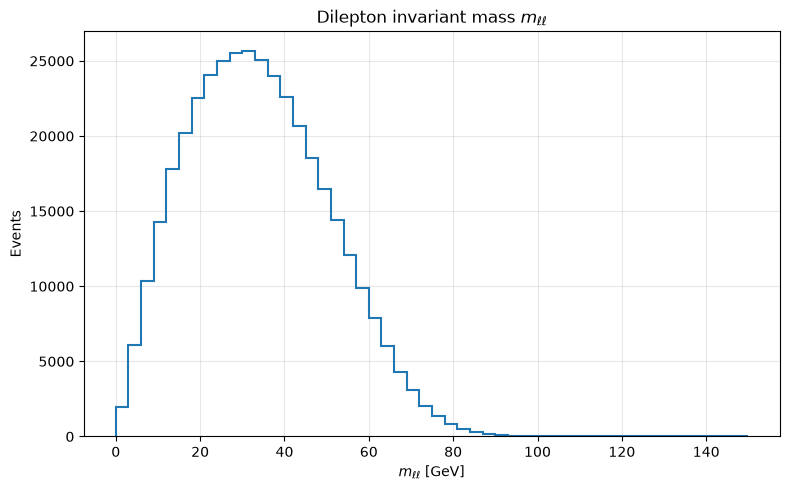

In [5]:
import matplotlib.pyplot as plt
import numpy as np

with uproot.open(path) as f:
    mll = f["Events"].arrays(["mll"], library="np")["mll"]

# Remove undefined values
mll = mll[mll > 0]

print("Number of entries:", len(mll))
print("Minimum:", np.min(mll))
print("Maximum:", np.max(mll))

plt.figure(figsize=(8, 5))

plt.hist(
    mll,
    bins=50,
    range=(0, 150),
    histtype="step",
    linewidth=1.5
)

plt.xlabel(r"$m_{\ell\ell}$ [GeV]")
plt.ylabel("Events")
plt.title(r"Dilepton invariant mass $m_{\ell\ell}$")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Number of entries: 192206
Minimum: 0.0
Maximum: 3.14151


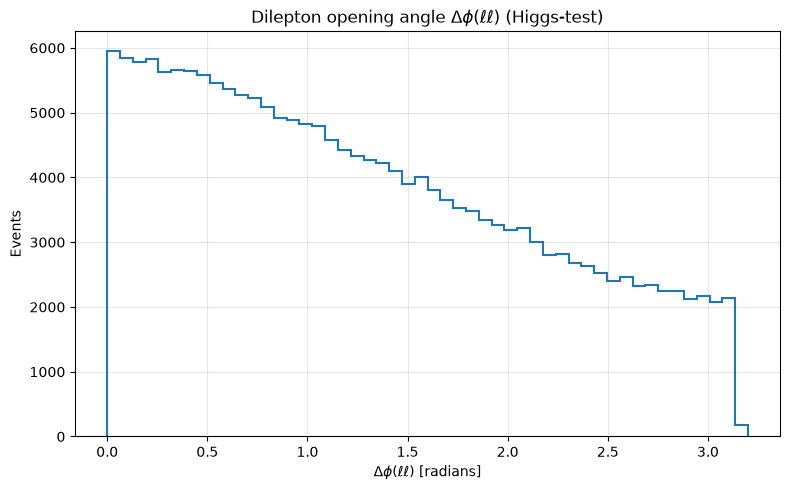

In [6]:
import matplotlib.pyplot as plt
import numpy as np

path = "/data/bvcoe2026/CMS-OD/samples/Higgs-test.root"

with uproot.open(path) as f:
    dphi = f["Events"].arrays(["dphill"], library="np")["dphill"]

# Keep physical values between 0 and pi (3.14)
dphi = dphi[(dphi >= 0) & (dphi <= 3.2)]

print("Number of entries:", len(dphi))
print("Minimum:", np.min(dphi))
print("Maximum:", np.max(dphi))

plt.figure(figsize=(8, 5))
plt.hist(dphi, bins=50, range=(0, 3.2), histtype="step", linewidth=1.5)
plt.xlabel(r"$\Delta\phi(\ell\ell)$ [radians]")
plt.ylabel("Events")
plt.title(r"Dilepton opening angle $\Delta\phi(\ell\ell)$ (Higgs-test)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Number of entries: 1507000
Minimum: 0.035993762
Maximum: 1172.4607


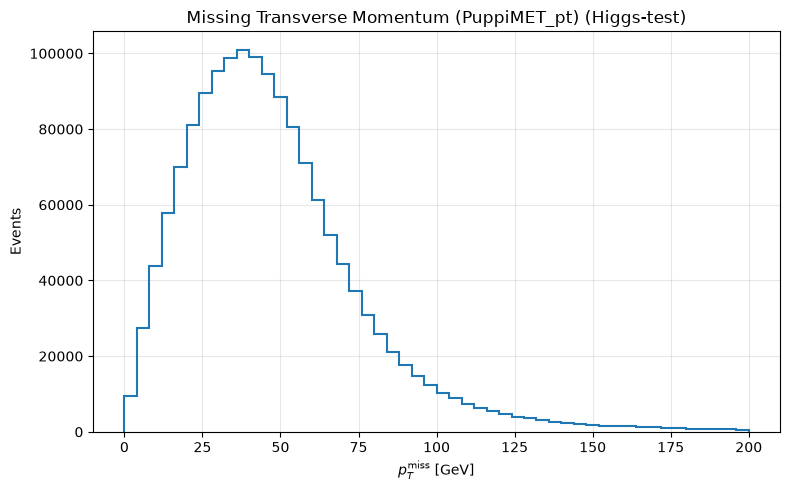

In [7]:
with uproot.open(path) as f:
    met = f["Events"].arrays(["PuppiMET_pt"], library="np")["PuppiMET_pt"]

# Filter out unphysical negative values
met = met[met >= 0]

print("Number of entries:", len(met))
print("Minimum:", np.min(met))
print("Maximum:", np.max(met))

plt.figure(figsize=(8, 5))
plt.hist(met, bins=50, range=(0, 200), histtype="step", linewidth=1.5)
plt.xlabel(r"$p_T^{\mathrm{miss}}$ [GeV]")
plt.ylabel("Events")
plt.title(r"Missing Transverse Momentum (PuppiMET_pt) (Higgs-test)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Number of entries: 383958
Minimum: 0.07683305
Maximum: 936.4624


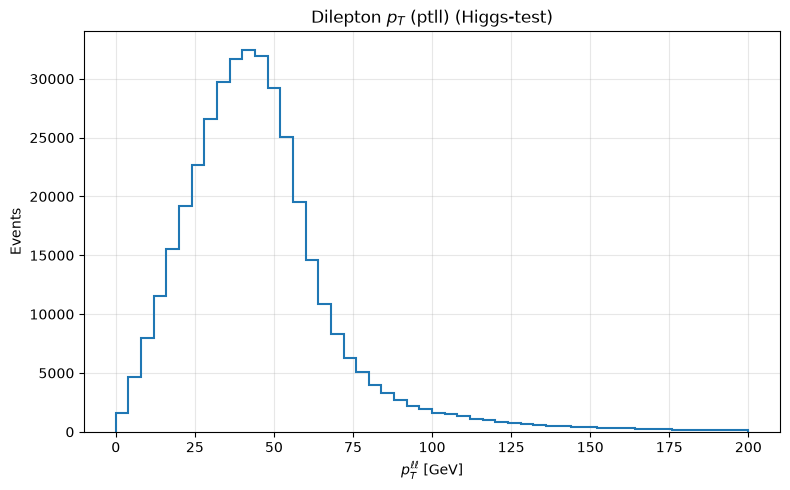

In [8]:
with uproot.open(path) as f:
    ptll = f["Events"].arrays(["ptll"], library="np")["ptll"]

ptll = ptll[ptll >= 0]

print("Number of entries:", len(ptll))
print("Minimum:", np.min(ptll))
print("Maximum:", np.max(ptll))

plt.figure(figsize=(8, 5))
plt.hist(ptll, bins=50, range=(0, 200), histtype="step", linewidth=1.5)
plt.xlabel(r"$p_T^{\ell\ell}$ [GeV]")
plt.ylabel("Events")
plt.title(r"Dilepton $p_T$ (ptll) (Higgs-test)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Number of entries: 383958
Minimum: 5.815304e-05
Maximum: 546.9156


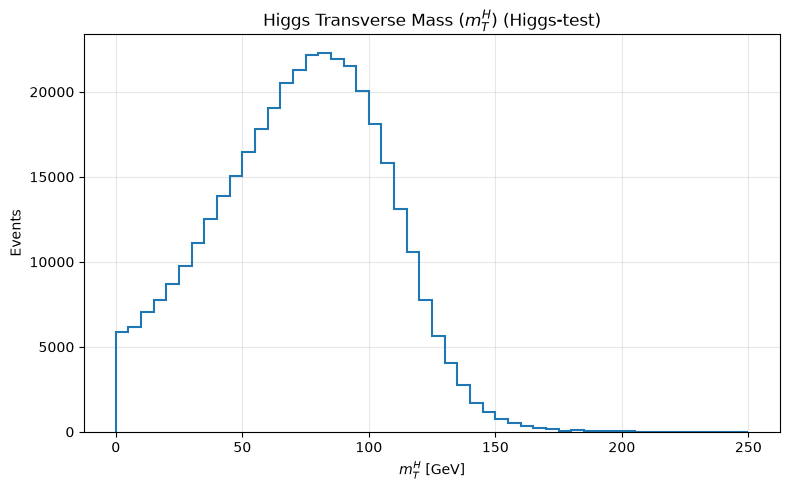

In [9]:
with uproot.open(path) as f:
    mth = f["Events"].arrays(["mth"], library="np")["mth"]

mth = mth[mth > 0]

print("Number of entries:", len(mth))
print("Minimum:", np.min(mth))
print("Maximum:", np.max(mth))

plt.figure(figsize=(8, 5))
plt.hist(mth, bins=50, range=(0, 250), histtype="step", linewidth=1.5)
plt.xlabel(r"$m_T^H$ [GeV]")
plt.ylabel("Events")
plt.title(r"Higgs Transverse Mass ($m_T^H$) (Higgs-test)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Number of entries: 1507000
Minimum jets: 0
Maximum jets: 19


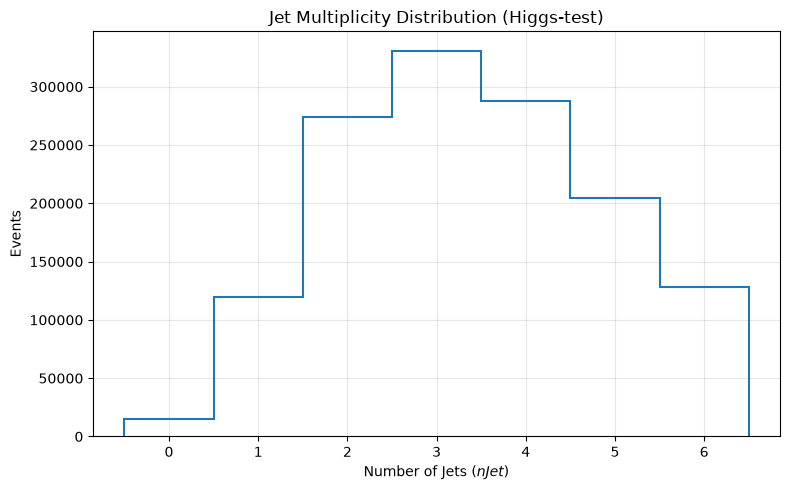

In [10]:
with uproot.open(path) as f:
    njet = f["Events"].arrays(["nJet"], library="np")["nJet"]

print("Number of entries:", len(njet))
print("Minimum jets:", np.min(njet))
print("Maximum jets:", np.max(njet))

plt.figure(figsize=(8, 5))
# Discrete bins from 0 to 6 jets
plt.hist(njet, bins=7, range=(-0.5, 6.5), histtype="step", linewidth=1.5, rwidth=0.8)
plt.xlabel("Number of Jets ($nJet$)")
plt.ylabel("Events")
plt.title("Jet Multiplicity Distribution (Higgs-test)")
plt.xticks(range(7))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Open the file
f = uproot.open("/data/bvcoe2026/CMS-OD/samples/Higgs-train.root")

# List the contents (keys)
print("Keys inside the file:")
print(f.keys())

Keys inside the file:
['Events;1']


In [12]:
tree = f["Events"]

print(f"Total collision events (rows): {tree.num_entries}\n")

# Display columns, types, and sizes
tree.show()

Total collision events (rows): 1439000

Events (ROOT::RNTuple)
├─ Electron_charge (std::vector<std::int32_t>)
├─ Electron_eta (std::vector<float>)
├─ Electron_mass (std::vector<float>)
├─ Electron_mvaFall17V2Iso_WP90 (std::vector<bool>)
├─ Electron_phi (std::vector<float>)
├─ Electron_pt (std::vector<float>)
├─ Jet_btagDeepFlavB (std::vector<float>)
├─ Jet_eta (std::vector<float>)
├─ Jet_jetId (std::vector<std::int32_t>)
├─ Jet_mass (std::vector<float>)
├─ Jet_phi (std::vector<float>)
├─ Jet_pt (std::vector<float>)
├─ Jet_puId (std::vector<std::int32_t>)
├─ Muon_charge (std::vector<std::int32_t>)
├─ Muon_eta (std::vector<float>)
├─ Muon_mass (std::vector<float>)
├─ Muon_pfRelIso04_all (std::vector<float>)
├─ Muon_phi (std::vector<float>)
├─ Muon_pt (std::vector<float>)
├─ Muon_tightId (std::vector<bool>)
├─ PuppiMET_phi (float)
├─ PuppiMET_pt (float)
├─ dphill (float)
├─ mjj (float)
├─ mll (float)
├─ mth (float)
├─ mtw2 (float)
├─ nJet (std::uint32_t)
└─ ptll (float)


Loaded Higgs-train.root
Loaded WW-train.root
Loaded Top-train.root
Loaded DY-train.root


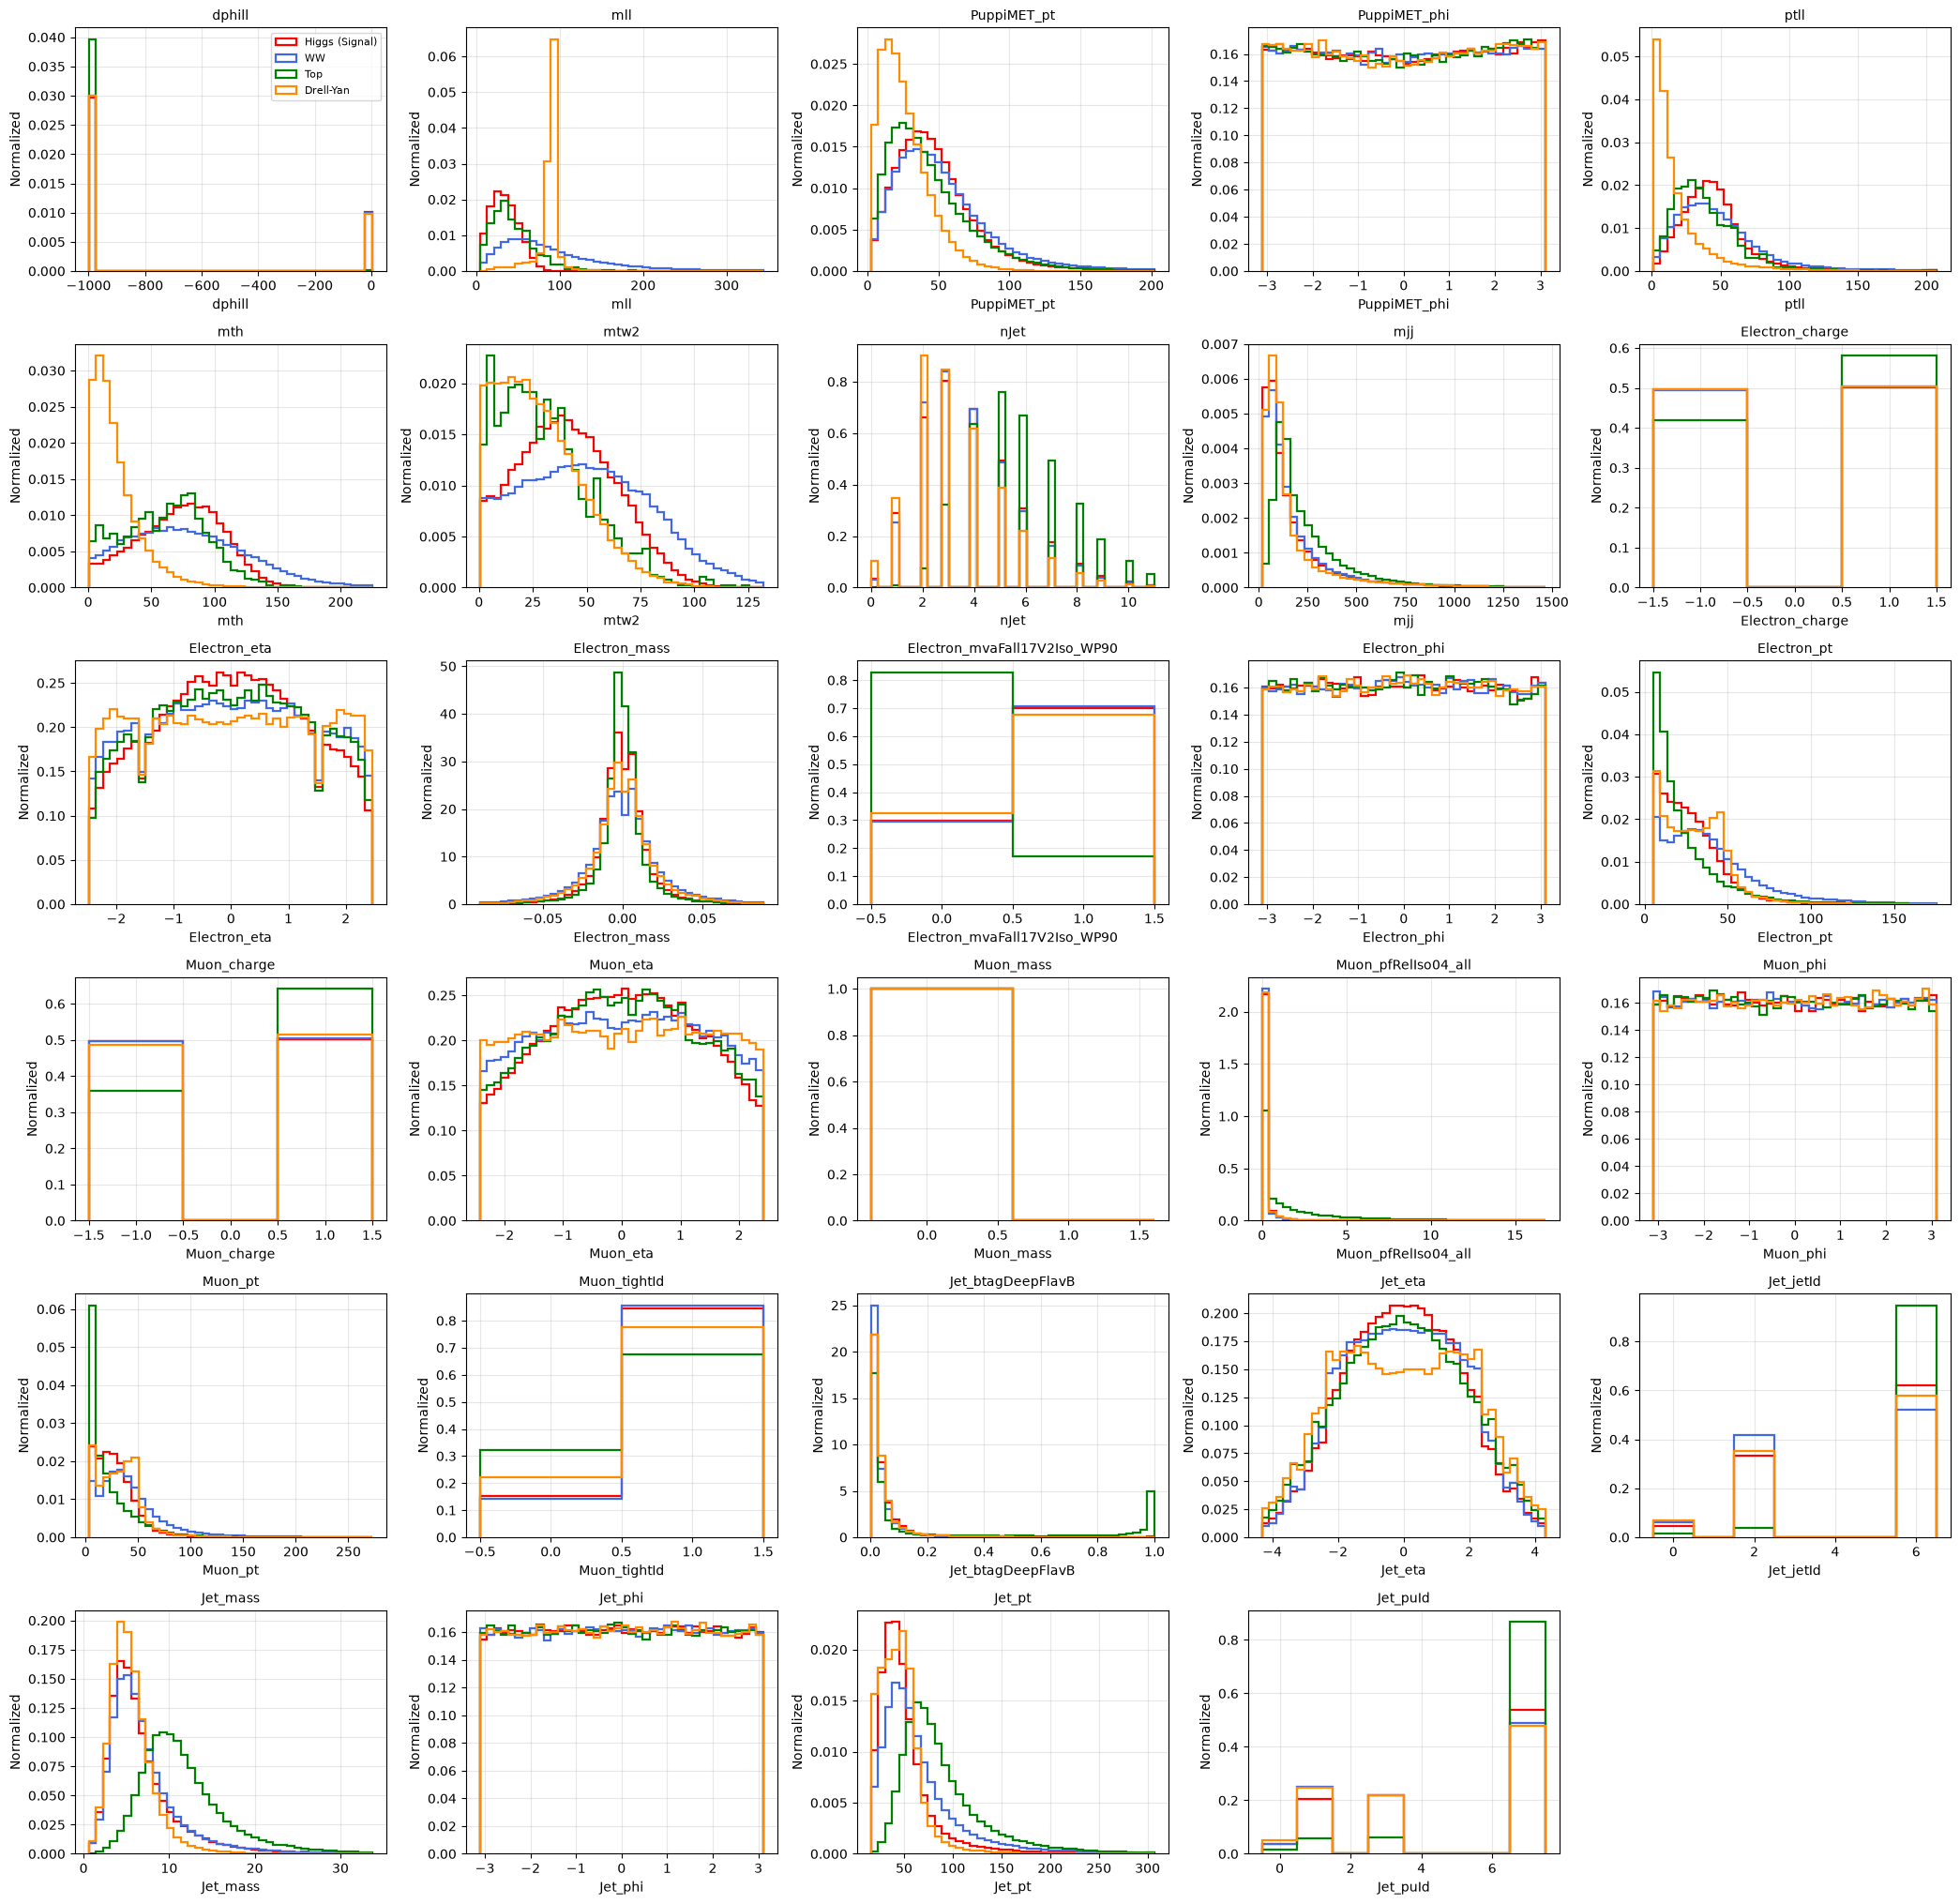

In [13]:
import uproot, awkward as ak, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
 
data_dir = Path("/data/bvcoe2026/CMS-OD/samples")
out_dir = Path("hackathon_results"); out_dir.mkdir(exist_ok=True)
MAX_EVENTS = 200_000   # first N events per file (same as the training notebook)
 
samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root",    "royalblue"),
    "Top":            ("Top-train.root",   "green"),
    "Drell-Yan":      ("DY-train.root",    "darkorange"),
}
 
scalar_branches = ["dphill","mll","PuppiMET_pt","PuppiMET_phi","ptll","mth","mtw2","nJet","mjj"]
vector_branches = [
    "Electron_charge","Electron_eta","Electron_mass","Electron_mvaFall17V2Iso_WP90","Electron_phi","Electron_pt",
    "Muon_charge","Muon_eta","Muon_mass","Muon_pfRelIso04_all","Muon_phi","Muon_pt","Muon_tightId",
    "Jet_btagDeepFlavB","Jet_eta","Jet_jetId","Jet_mass","Jet_phi","Jet_pt","Jet_puId",
]
features = scalar_branches + vector_branches
POSITIVE_ONLY = {"mll","mth","mtw2","ptll","mjj","PuppiMET_pt"}   
 
# ---- load once: one 1D array per feature per sample (vectors -> leading object) ----
data = {lab: {} for lab in samples}
for lab, (fn, _) in samples.items():
    with uproot.open(data_dir / fn) as f:
        arrs = f["Events"].arrays(features, library="ak", entry_stop=MAX_EVENTS)
    for v in features:
        if v in vector_branches:
            x = ak.to_numpy(ak.drop_none(ak.firsts(arrs[v]))).astype(float)   # events with no object are skipped
        else:
            x = ak.to_numpy(arrs[v]).astype(float)
            if v in POSITIVE_ONLY:
                x = x[x > 0]
        data[lab][v] = x[np.isfinite(x)]
    print("Loaded", fn)
 
# ---- plot every feature, normalized so shapes are comparable ----
def pick_bins(v, arrays):
    pooled = np.concatenate([a for a in arrays if len(a)])
    uniq = np.unique(pooled)
    if len(uniq) <= 12:                                     # discrete (charge, ids, flags, nJet...)
        return np.arange(uniq.min() - 0.5, uniq.max() + 1.5, 1.0)
    lo, hi = np.percentile(pooled, [0.5, 99.5])             # trim outliers
    return np.linspace(lo, hi, 41)
 
def draw(ax, v):
    bins = pick_bins(v, [data[l][v] for l in samples])
    for lab, (_, color) in samples.items():
        x = data[lab][v]
        if len(x):
            ax.hist(x, bins=bins, histtype="step", lw=1.6, density=True, color=color, label=lab)
    ax.set_xlabel(v); ax.set_ylabel("Normalized"); ax.grid(alpha=0.3)
 
# 1) one PNG per feature
for v in features:
    fig, ax = plt.subplots(figsize=(7, 5))
    draw(ax, v); ax.set_title(f"{v} (Signal vs Background)"); ax.legend(frameon=True)
    fig.tight_layout(); fig.savefig(out_dir / f"superimposed_{v}.png", dpi=150); plt.close(fig)
 
# 2) one big grid
ncols = 5; nrows = int(np.ceil(len(features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows))
for ax, v in zip(axes.ravel(), features):
    draw(ax, v); ax.set_title(v, fontsize=10)
for ax in axes.ravel()[len(features):]: ax.axis("off")
axes.ravel()[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(out_dir / "all_features_superimposed.png", dpi=130); plt.show()

In [14]:
!pip install -q xgboost scikit-learn scipy

In [15]:
import os
import numpy as np
import pandas as pd
import awkward as ak
import uproot
import matplotlib.pyplot as plt
from pathlib import Path

from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score
from xgboost import XGBClassifier

mvaVariables = [
    "Electron_charge", "Electron_eta", "Electron_mass", "Electron_mvaFall17V2Iso_WP90",
    "Electron_phi", "Electron_pt",
    "Jet_btagDeepFlavB", "Jet_eta", "Jet_jetId", "Jet_mass", "Jet_phi", "Jet_pt", "Jet_puId",
    "Muon_charge", "Muon_eta", "Muon_mass", "Muon_pfRelIso04_all", "Muon_phi", "Muon_pt", "Muon_tightId",
    "PuppiMET_phi", "PuppiMET_pt",          
    "dphill", "mjj", "mll", "mth", "mtw2", "nJet", "ptll",
]

JAGGED_PREFIXES = ("Electron_", "Muon_", "Jet_")
def is_jagged(name): return name.startswith(JAGGED_PREFIXES)

In [16]:
data_dir = Path("/data/bvcoe2026/CMS-OD/samples")


SAMPLE_FILES = {
    "Higgs_train": "Higgs-train.root",  "Higgs_test": "Higgs-test.root",
    "DY_train":    "DY-train.root",     "DY_test":    "DY-test.root",
    "Top_train":   "Top-train.root",    "Top_test":   "Top-test.root",
    "WW_train":    "WW-train.root",     "WW_test":    "WW-test.root",
}

LABELS = {                       
    "Higgs_train": 1, "Higgs_test": 1,
    "DY_train": 0,    "DY_test": 0,
    "Top_train": 0,   "Top_test": 0,
    "WW_train": 0,    "WW_test": 0,
}

PROCESS_SAMPLES = ["Higgs_train", "DY_train", "Top_train", "WW_train"]

TRAIN_SAMPLES = ["Higgs_train", "DY_train", "Top_train", "WW_train"]
TEST_SAMPLES  = ["Higgs_test",  "DY_test",  "Top_test",  "WW_test"]

In [24]:
XGB_CONFIGS = {
    #"xgb_d5_lr03_n700_dense": {
        #"n_estimators": 700, "max_depth": 5, "learning_rate": 0.03,
        #"subsample": 0.85, "colsample_bytree": 0.75,
        #"min_child_weight": 5, "reg_lambda": 2.0, "gamma": 0.5},
    "xgb_d6_lr03_n600_l2": {"n_estimators": 600, "max_depth": 6, "learning_rate": 0.03,
      "subsample": 0.8, "colsample_bytree": 0.7, "min_child_weight": 8, "reg_lambda": 3.0, "gamma": 1.5},
    #"xgb_d6_lr03_n700_l1l2": {"n_estimators": 700, "max_depth": 6, "learning_rate": 0.03,
      #"subsample": 0.8, "colsample_bytree": 0.7, "min_child_weight": 10, "reg_alpha": 0.5, "reg_lambda": 2.0, "gamma": 1.0},
}

OUTDIR = Path("bdt_output"); OUTDIR.mkdir(exist_ok=True)

In [18]:
def load_one(sample, max_events=200_000):
    """Return (X, y) for one logical sample using mvaVariables as columns."""
    with uproot.open(data_dir / SAMPLE_FILES[sample]) as f:
        tree = f["Events"]
        arrs = tree.arrays(mvaVariables, library="ak", entry_stop=max_events)

    cols = []
    for v in mvaVariables:
        if is_jagged(v):
            x = ak.to_numpy(ak.fill_none(ak.firsts(arrs[v]), np.nan)).astype(np.float64)
        else:
            x = ak.to_numpy(arrs[v]).astype(np.float64)
            if v in ("mll", "mth", "mtw2", "ptll", "mjj", "PuppiMET_pt"):
                x = np.where(x <= 0, np.nan, x)   
        cols.append(x)

    X = np.column_stack(cols)
    y = np.full(len(X), LABELS[sample], dtype=int)
    return X, y

def build(sample_list):
    Xs, ys = zip(*(load_one(s) for s in sample_list))
    return np.vstack(Xs), np.concatenate(ys)

X_train, y_train = build(TRAIN_SAMPLES)
X_test,  y_test  = build(TEST_SAMPLES)
print("train:", X_train.shape, "signal frac", round(y_train.mean(), 3))
print("test :", X_test.shape,  "signal frac", round(y_test.mean(), 3))

train: (800000, 29) signal frac 0.25
test : (800000, 29) signal frac 0.25


In [19]:
def separation(sig, bkg, bins=50):
    both = np.concatenate([sig, bkg]); both = both[~np.isnan(both)]
    lo, hi = np.nanpercentile(both, [1, 99])
    s, _ = np.histogram(sig[~np.isnan(sig)], bins=bins, range=(lo, hi), density=True)
    b, _ = np.histogram(bkg[~np.isnan(bkg)], bins=bins, range=(lo, hi), density=True)
    s, b = s / s.sum(), b / b.sum()
    d = s + b
    return 0.5 * np.sum((s - b) ** 2 / np.where(d > 0, d, 1))

# rank every feature
scores = {v: separation(X_train[y_train == 1, i], X_train[y_train == 0, i])
          for i, v in enumerate(mvaVariables)}
ranked = sorted(scores.items(), key=lambda kv: -kv[1])
for v, s in ranked:
    print(f"{v:28s} {s:.4f}")

#THRESH = 0.02
#selected = [v for v, s in ranked if s >= THRESH]     
selected = [v for v, s in ranked[:10]]              

sel_idx = [mvaVariables.index(v) for v in selected]
print("\nselected:", selected)

Xtr, Xte = X_train[:, sel_idx], X_test[:, sel_idx]
feat_names = np.array(selected)

mll                          0.5693
mth                          0.1937
ptll                         0.1615
Jet_pt                       0.0701
Muon_pfRelIso04_all          0.0393
Electron_mvaFall17V2Iso_WP90 0.0374
mjj                          0.0354
Muon_pt                      0.0349
PuppiMET_pt                  0.0349
Jet_btagDeepFlavB            0.0317
Jet_mass                     0.0281
mtw2                         0.0277
Electron_pt                  0.0214
nJet                         0.0137
dphill                       0.0130
Electron_mass                0.0089
Muon_tightId                 0.0075
Jet_puId                     0.0069
Muon_mass                    0.0068
Jet_eta                      0.0060
Jet_jetId                    0.0052
Electron_eta                 0.0040
Muon_eta                     0.0030
Muon_charge                  0.0020
Electron_charge              0.0008
Electron_phi                 0.0002
Muon_phi                     0.0002
Jet_phi                     

## Feature correlation matrix
Linear (Pearson) correlations, shown separately for signal and background since they differ.

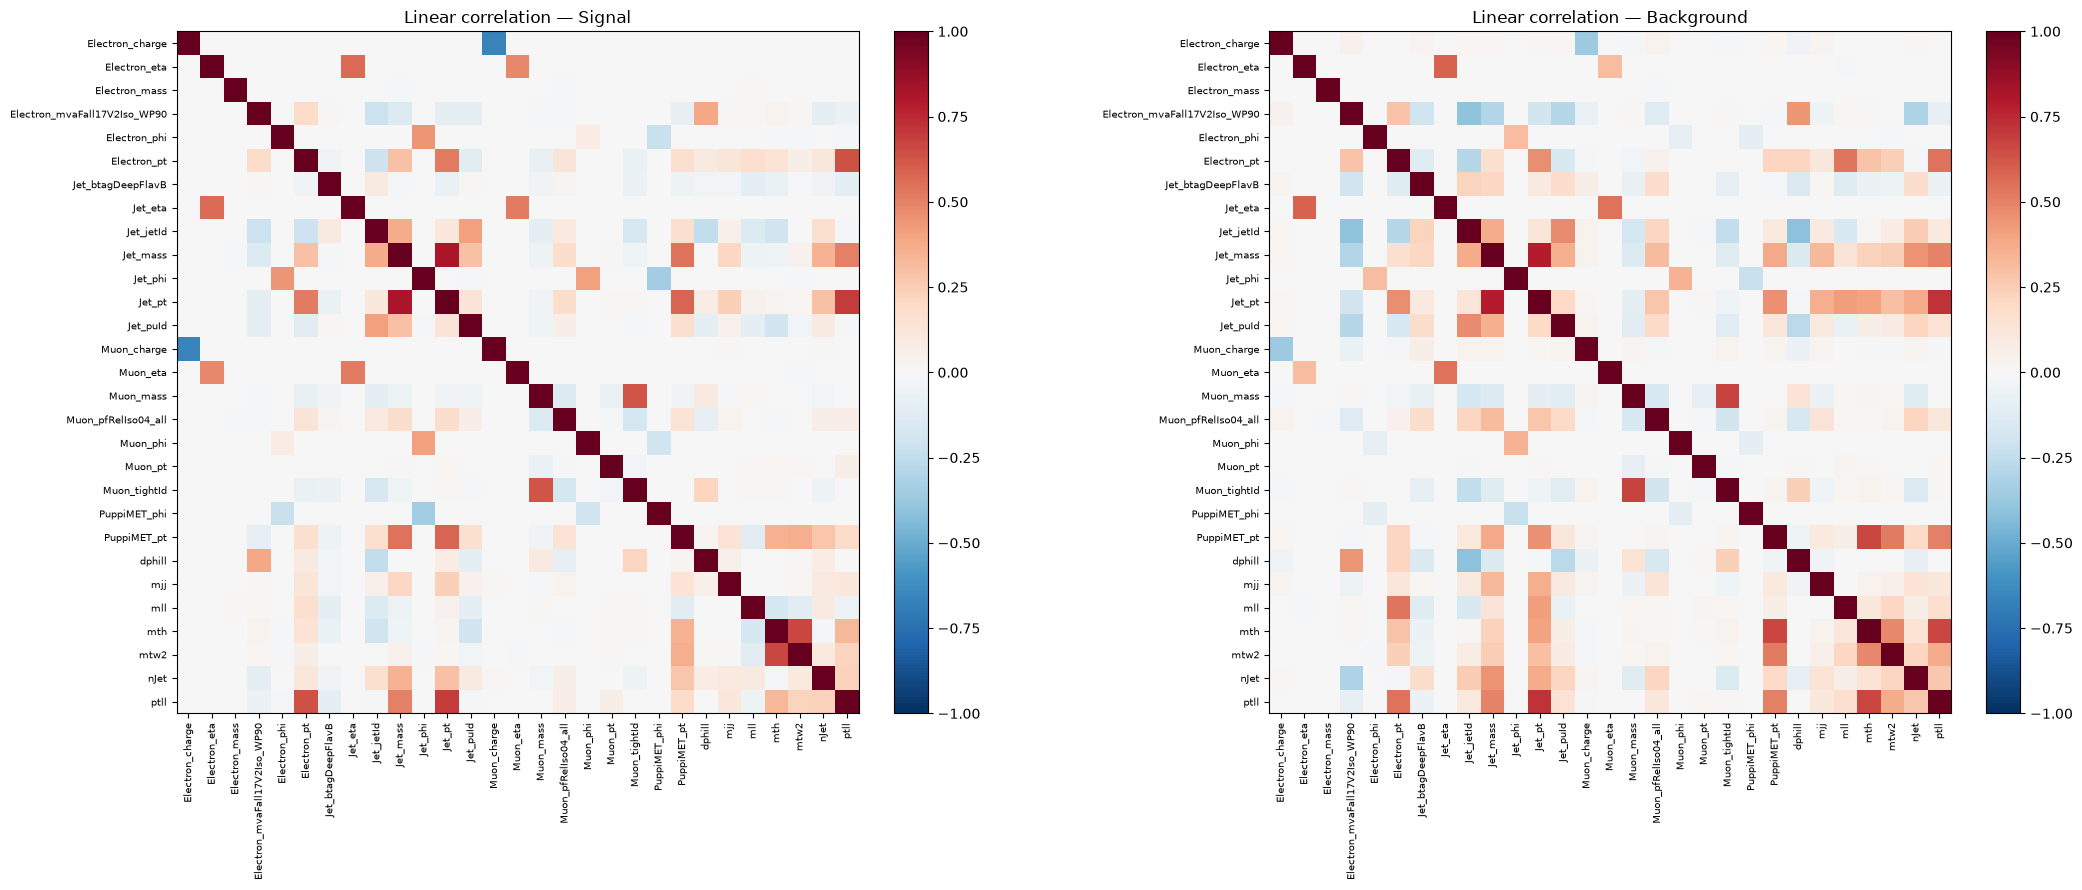

In [20]:
df = pd.DataFrame(X_train, columns=mvaVariables)

fig, ax = plt.subplots(1, 2, figsize=(22, 9))
for a, mask, title in [(ax[0], y_train == 1, "Signal"), (ax[1], y_train == 0, "Background")]:
    corr = df[mask].corr()                      
    im = a.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    a.set_xticks(range(len(mvaVariables))); a.set_xticklabels(mvaVariables, rotation=90, fontsize=7)
    a.set_yticks(range(len(mvaVariables))); a.set_yticklabels(mvaVariables, fontsize=7)
    a.set_title(f"Linear correlation \u2014 {title}")
    fig.colorbar(im, ax=a, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(OUTDIR / "correlation_matrix.png", dpi=120)
plt.show()

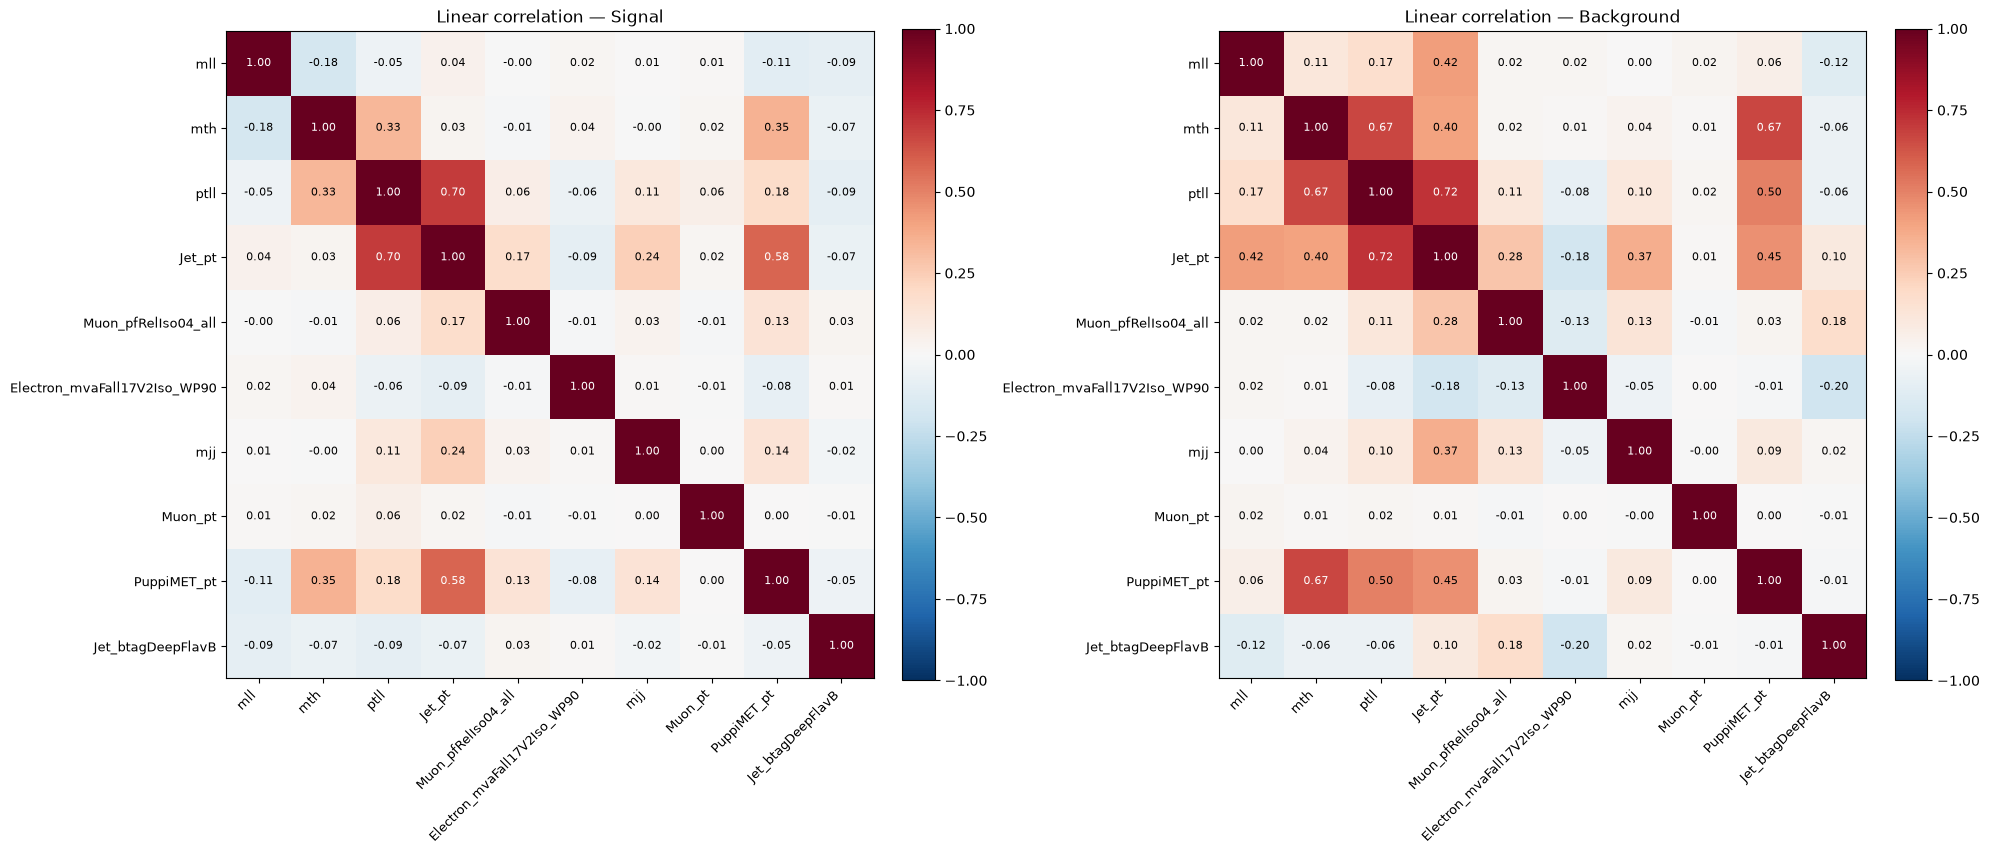

In [21]:
df = pd.DataFrame(Xtr, columns=feat_names)

fig, ax = plt.subplots(1, 2, figsize=(20, 9))
for a, mask, title in [(ax[0], y_train == 1, "Signal"), (ax[1], y_train == 0, "Background")]:
    corr = df[mask].corr().values
    n = len(feat_names)
    im = a.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")

    # write the number in every cell
    for i in range(n):
        for j in range(n):
            val = corr[i, j]
            a.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8,
                   color="white" if abs(val) > 0.55 else "black")

    a.set_xticks(range(n)); a.set_xticklabels(feat_names, rotation=45, ha="right", fontsize=9)
    a.set_yticks(range(n)); a.set_yticklabels(feat_names, fontsize=9)
    a.set_title(f"Linear correlation — {title}")
    fig.colorbar(im, ax=a, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(OUTDIR / "correlation_matrix.png", dpi=120)
plt.show()

## Train the BDT
ROC + AUC (train vs test) and an overtraining check with the two-sample KS test on the classifier scores.
`p > 0.05` => train/test score distributions compatible (no significant overtraining).


=== xgb_d5_lr03_n700_dense ===
[0]	validation_0-auc:0.71402	validation_1-auc:0.71227
[50]	validation_0-auc:0.79934	validation_1-auc:0.79817
[100]	validation_0-auc:0.80699	validation_1-auc:0.80565
[150]	validation_0-auc:0.81172	validation_1-auc:0.81012
[200]	validation_0-auc:0.81532	validation_1-auc:0.81344
[250]	validation_0-auc:0.81810	validation_1-auc:0.81584
[300]	validation_0-auc:0.81999	validation_1-auc:0.81739
[350]	validation_0-auc:0.82156	validation_1-auc:0.81861
[400]	validation_0-auc:0.82273	validation_1-auc:0.81945
[450]	validation_0-auc:0.82377	validation_1-auc:0.82017
[500]	validation_0-auc:0.82495	validation_1-auc:0.82104
[550]	validation_0-auc:0.82594	validation_1-auc:0.82171
[600]	validation_0-auc:0.82680	validation_1-auc:0.82227
[650]	validation_0-auc:0.82769	validation_1-auc:0.82284
[699]	validation_0-auc:0.82850	validation_1-auc:0.82336
AUC train 0.8285 | test 0.8234 | acc test 0.7076
KS p-value  signal=0.000  background=0.001  (p>0.05 => compatible, no overtraining

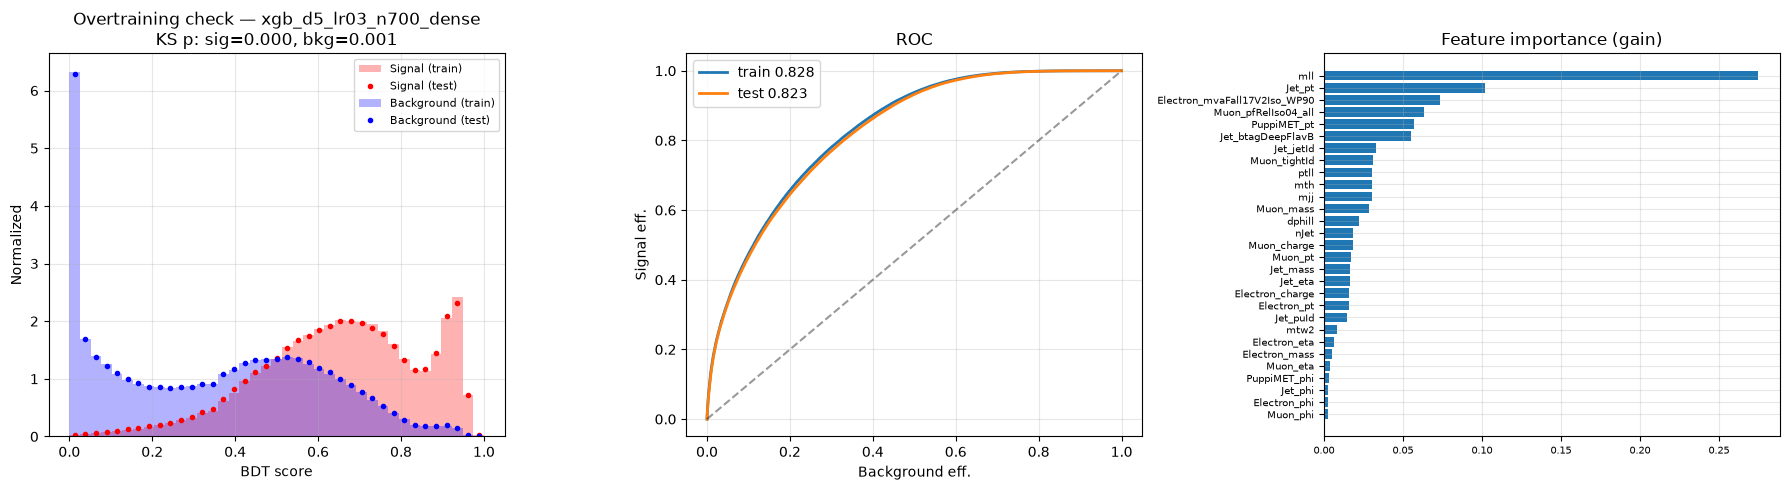

saved -> bdt_output/xgb_d5_lr03_n700_dense.json

=== xgb_d6_lr03_n600_l2 ===
[0]	validation_0-auc:0.73898	validation_1-auc:0.73656
[50]	validation_0-auc:0.80570	validation_1-auc:0.80407
[100]	validation_0-auc:0.81230	validation_1-auc:0.81037
[150]	validation_0-auc:0.81711	validation_1-auc:0.81464
[200]	validation_0-auc:0.82049	validation_1-auc:0.81750
[250]	validation_0-auc:0.82274	validation_1-auc:0.81924
[300]	validation_0-auc:0.82475	validation_1-auc:0.82067
[350]	validation_0-auc:0.82644	validation_1-auc:0.82179
[400]	validation_0-auc:0.82778	validation_1-auc:0.82258
[450]	validation_0-auc:0.82906	validation_1-auc:0.82331
[500]	validation_0-auc:0.83039	validation_1-auc:0.82408
[550]	validation_0-auc:0.83165	validation_1-auc:0.82482
[599]	validation_0-auc:0.83277	validation_1-auc:0.82541
AUC train 0.8328 | test 0.8254 | acc test 0.7090
KS p-value  signal=0.000  background=0.000  (p>0.05 => compatible, no overtraining)


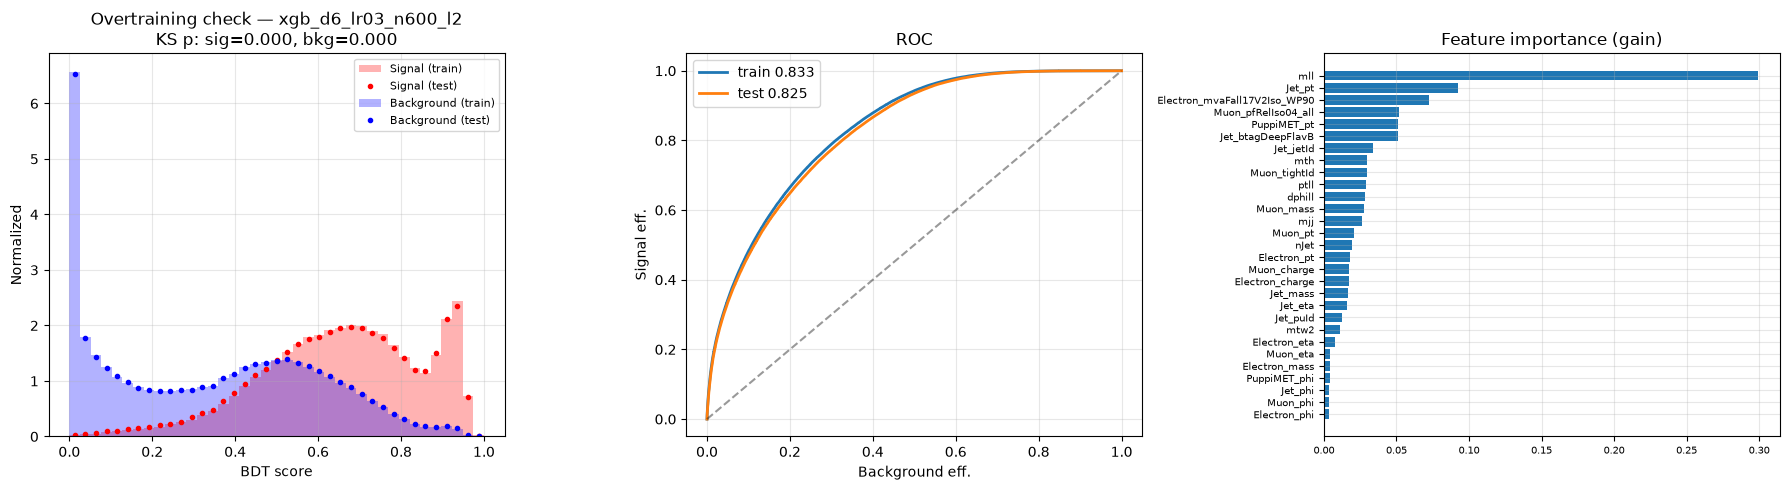

saved -> bdt_output/xgb_d6_lr03_n600_l2.json

=== xgb_d6_lr03_n700_l1l2 ===
[0]	validation_0-auc:0.73897	validation_1-auc:0.73658
[50]	validation_0-auc:0.80568	validation_1-auc:0.80407
[100]	validation_0-auc:0.81229	validation_1-auc:0.81038
[150]	validation_0-auc:0.81708	validation_1-auc:0.81468
[200]	validation_0-auc:0.82046	validation_1-auc:0.81753
[250]	validation_0-auc:0.82275	validation_1-auc:0.81930
[300]	validation_0-auc:0.82468	validation_1-auc:0.82064
[350]	validation_0-auc:0.82641	validation_1-auc:0.82180
[400]	validation_0-auc:0.82770	validation_1-auc:0.82253
[450]	validation_0-auc:0.82901	validation_1-auc:0.82328
[500]	validation_0-auc:0.83037	validation_1-auc:0.82407
[550]	validation_0-auc:0.83165	validation_1-auc:0.82481
[600]	validation_0-auc:0.83278	validation_1-auc:0.82539
[650]	validation_0-auc:0.83398	validation_1-auc:0.82604
[699]	validation_0-auc:0.83495	validation_1-auc:0.82653
AUC train 0.8350 | test 0.8265 | acc test 0.7107
KS p-value  signal=0.000  background=0

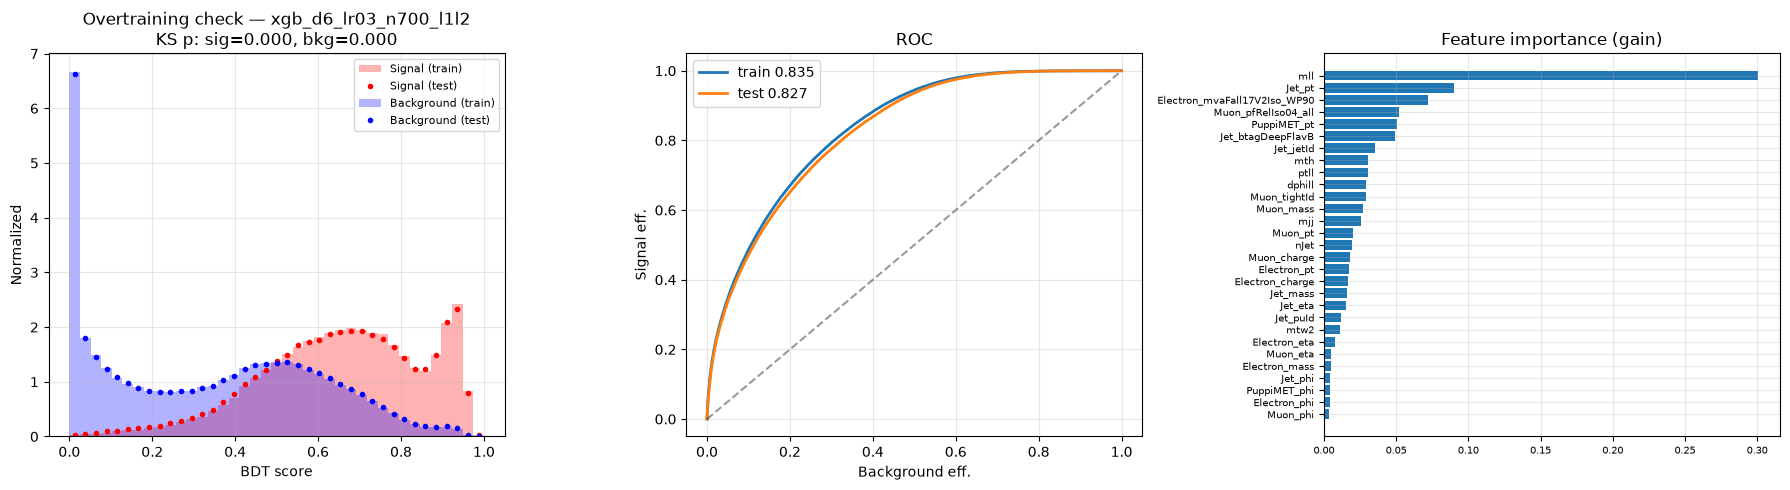

saved -> bdt_output/xgb_d6_lr03_n700_l1l2.json


In [22]:
def train_bdt():
    spw = (y_train == 0).sum() / max((y_train == 1).sum(), 1)   

    for name, cfg in XGB_CONFIGS.items():
        print(f"\n=== {name} ===")
        model = XGBClassifier(
            **cfg, scale_pos_weight=spw, eval_metric="auc",
            n_jobs=-1, random_state=42,
        )
        model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_test, y_test)], verbose=50)

        p_tr = model.predict_proba(X_train)[:, 1]
        p_te = model.predict_proba(X_test)[:, 1]
        auc_tr = roc_auc_score(y_train, p_tr)
        auc_te = roc_auc_score(y_test,  p_te)
        print(f"AUC train {auc_tr:.4f} | test {auc_te:.4f} | acc test {accuracy_score(y_test, p_te>0.5):.4f}")

        # KS test: are train and test score distributions compatible? (per class)
        ks_sig = ks_2samp(p_tr[y_train == 1], p_te[y_test == 1])
        ks_bkg = ks_2samp(p_tr[y_train == 0], p_te[y_test == 0])
        print(f"KS p-value  signal={ks_sig.pvalue:.3f}  background={ks_bkg.pvalue:.3f}  "
              f"(p>0.05 => compatible, no overtraining)")

        fig, ax = plt.subplots(1, 3, figsize=(18, 5))

        # (1) Overtraining check: train (filled) vs test (points), per class, with KS p-values
        bins = np.linspace(0, 1, 40)
        for lbl, col, tag in [(1, "red", "Signal"), (0, "blue", "Background")]:
            ax[0].hist(p_tr[y_train == lbl], bins=bins, density=True, histtype="stepfilled",
                       alpha=0.3, color=col, label=f"{tag} (train)")
            h, _ = np.histogram(p_te[y_test == lbl], bins=bins, density=True)
            c = 0.5 * (bins[1:] + bins[:-1])
            ax[0].plot(c, h, "o", ms=3, color=col, label=f"{tag} (test)")
        ax[0].set(xlabel="BDT score", ylabel="Normalized",
                  title=f"Overtraining check \u2014 {name}\nKS p: sig={ks_sig.pvalue:.3f}, bkg={ks_bkg.pvalue:.3f}")
        ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

        # (2) ROC, train vs test
        for p, yv, tag, c in [(p_tr, y_train, f"train {auc_tr:.3f}", "C0"),
                              (p_te, y_test,  f"test {auc_te:.3f}",  "C1")]:
            fpr, tpr, _ = roc_curve(yv, p); ax[1].plot(fpr, tpr, color=c, lw=2, label=tag)
        ax[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
        ax[1].set(xlabel="Background eff.", ylabel="Signal eff.", title="ROC"); ax[1].legend(); ax[1].grid(alpha=0.3)

        # (3) Feature importance
        imp = model.feature_importances_; order = np.argsort(imp)
        ax[2].barh(np.array(mvaVariables)[order], imp[order])
        ax[2].set(title="Feature importance (gain)"); ax[2].tick_params(labelsize=7); ax[2].grid(alpha=0.3)

        plt.tight_layout()
        fig.savefig(OUTDIR / f"{name}_plots.png", dpi=120)
        plt.show()

        # Save the trained model
        model.save_model(OUTDIR / f"{name}.json")
        print(f"saved -> {OUTDIR/name}.json")

train_bdt()


=== xgb_d6_lr03_n600_l2 ===
[0]	validation_0-auc:0.74432	validation_1-auc:0.74325
[50]	validation_0-auc:0.80147	validation_1-auc:0.80018
[100]	validation_0-auc:0.80498	validation_1-auc:0.80351
[150]	validation_0-auc:0.80726	validation_1-auc:0.80549
[200]	validation_0-auc:0.80910	validation_1-auc:0.80693
[250]	validation_0-auc:0.81043	validation_1-auc:0.80787
[300]	validation_0-auc:0.81143	validation_1-auc:0.80848
[350]	validation_0-auc:0.81225	validation_1-auc:0.80890
[400]	validation_0-auc:0.81296	validation_1-auc:0.80919
[450]	validation_0-auc:0.81361	validation_1-auc:0.80946
[500]	validation_0-auc:0.81421	validation_1-auc:0.80965
[550]	validation_0-auc:0.81472	validation_1-auc:0.80978
[599]	validation_0-auc:0.81530	validation_1-auc:0.80994
AUC train 0.8153 | test 0.8099 | acc test 0.6921
KS p-value  signal=0.000  background=0.001  (p>0.05 => compatible, no overtraining)


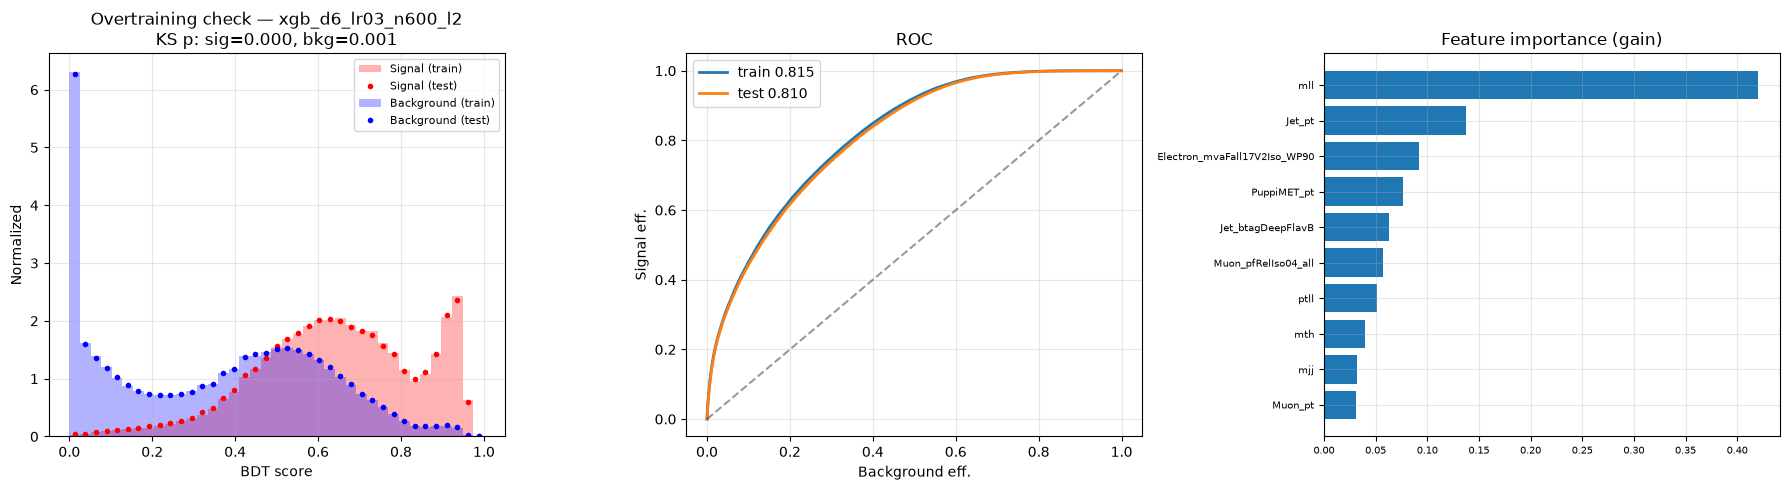

saved -> bdt_output/xgb_d6_lr03_n600_l2.json


In [25]:
def train_bdt():
    spw = (y_train == 0).sum() / max((y_train == 1).sum(), 1)   

    for name, cfg in XGB_CONFIGS.items():
        print(f"\n=== {name} ===")
        model = XGBClassifier(
            **cfg, scale_pos_weight=spw, eval_metric="auc",
            n_jobs=-1, random_state=42,
        )
        model.fit(Xtr, y_train, eval_set=[(Xtr, y_train), (Xte, y_test)], verbose=50)

        p_tr = model.predict_proba(Xtr)[:, 1]
        p_te = model.predict_proba(Xte)[:, 1]
        auc_tr = roc_auc_score(y_train, p_tr)
        auc_te = roc_auc_score(y_test,  p_te)
        print(f"AUC train {auc_tr:.4f} | test {auc_te:.4f} | acc test {accuracy_score(y_test, p_te>0.5):.4f}")

        # KS test: are train and test score distributions compatible? (per class)
        ks_sig = ks_2samp(p_tr[y_train == 1], p_te[y_test == 1])
        ks_bkg = ks_2samp(p_tr[y_train == 0], p_te[y_test == 0])
        print(f"KS p-value  signal={ks_sig.pvalue:.3f}  background={ks_bkg.pvalue:.3f}  "
              f"(p>0.05 => compatible, no overtraining)")

        fig, ax = plt.subplots(1, 3, figsize=(18, 5))

        # (1) Overtraining check: train (filled) vs test (points), per class, with KS p-values
        bins = np.linspace(0, 1, 40)
        for lbl, col, tag in [(1, "red", "Signal"), (0, "blue", "Background")]:
            ax[0].hist(p_tr[y_train == lbl], bins=bins, density=True, histtype="stepfilled",
                       alpha=0.3, color=col, label=f"{tag} (train)")
            h, _ = np.histogram(p_te[y_test == lbl], bins=bins, density=True)
            c = 0.5 * (bins[1:] + bins[:-1])
            ax[0].plot(c, h, "o", ms=3, color=col, label=f"{tag} (test)")
        ax[0].set(xlabel="BDT score", ylabel="Normalized",
                  title=f"Overtraining check \u2014 {name}\nKS p: sig={ks_sig.pvalue:.3f}, bkg={ks_bkg.pvalue:.3f}")
        ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

        # (2) ROC, train vs test
        for p, yv, tag, c in [(p_tr, y_train, f"train {auc_tr:.3f}", "C0"),
                              (p_te, y_test,  f"test {auc_te:.3f}",  "C1")]:
            fpr, tpr, _ = roc_curve(yv, p); ax[1].plot(fpr, tpr, color=c, lw=2, label=tag)
        ax[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
        ax[1].set(xlabel="Background eff.", ylabel="Signal eff.", title="ROC"); ax[1].legend(); ax[1].grid(alpha=0.3)

        # (3) Feature importance
        imp = model.feature_importances_; order = np.argsort(imp)
        ax[2].barh(np.array(feat_names)[order], imp[order])
        ax[2].set(title="Feature importance (gain)"); ax[2].tick_params(labelsize=7); ax[2].grid(alpha=0.3)

        plt.tight_layout()
        fig.savefig(OUTDIR / f"{name}_plots.png", dpi=120)
        plt.show()

        # Save the trained model
        model.save_model(OUTDIR / f"{name}.json")
        print(f"saved -> {OUTDIR/name}.json")

train_bdt()